# Лабораторная работа № 2. Классификация пассажиров Titanic

**Цель.** Предсказать выживание пассажира (`Survived=1`) и сравнить пять классификаторов с базовой моделью. Основная метрика — F1 для положительного класса.

**Данные.** [Titanic Dataset](https://www.kaggle.com/datasets/yasserh/titanic-dataset), 891 размеченная запись. Исследование проводится на собственном стратифицированном разбиении 80/20. [Задание](https://github.com/lesopylka/ml_course_mai/blob/main/classification/lab02.pdf).

## 1. Библиотеки и настройки

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
pd.set_option('display.precision', 4)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})

## 2. Анализ исходных данных

In [2]:
data = pd.read_csv(Path('../data/Titanic-Dataset.csv'))
assert data.shape == (891, 12)
assert set(data['Survived']) == {0, 1}
print('размер таблицы:', data.shape)
display(data.head())

размер таблицы: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
overview = pd.DataFrame({
    'тип': data.dtypes.astype(str),
    'пропуски': data.isna().sum(),
    'уникальных значений': data.nunique(dropna=True),
})
display(overview)
print('полных дубликатов:', data.duplicated().sum())

,тип,пропуски,уникальных значений
PassengerId,int64,0,891
Survived,int64,0,2
Pclass,int64,0,3
Name,str,0,891
Sex,str,0,2
Age,float64,177,88
SibSp,int64,0,7
Parch,int64,0,7
Ticket,str,0,681
Fare,float64,0,248


полных дубликатов: 0


,пассажиров
Survived,
не выжил,549
выжил,342


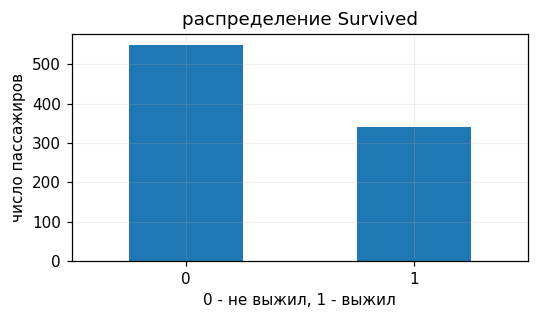

In [4]:
class_counts = data['Survived'].value_counts().sort_index()
display(class_counts.rename(index={0: 'не выжил', 1: 'выжил'}).to_frame('пассажиров'))
class_counts.plot.bar(rot=0, figsize=(5, 3), title='распределение Survived')
plt.xlabel('0 - не выжил, 1 - выжил')
plt.ylabel('число пассажиров')
plt.tight_layout(); plt.show()

,count,доля выживших
Sex,,
female,314,0.7420
male,577,0.1889


,count,доля выживших
Pclass,,
1,216,0.6296
2,184,0.4728
3,491,0.2424


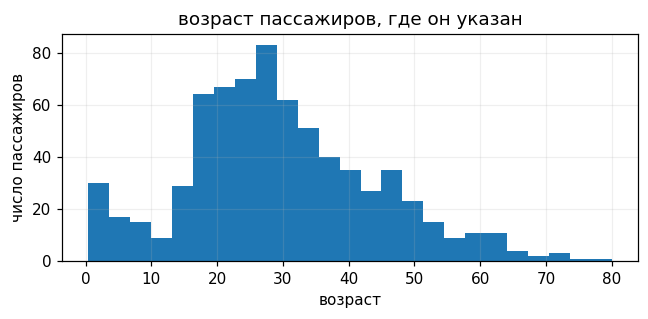

In [5]:
display(data.groupby('Sex')['Survived'].agg(['count', 'mean']).rename(columns={'mean':'доля выживших'}))
display(data.groupby('Pclass')['Survived'].agg(['count', 'mean']).rename(columns={'mean':'доля выживших'}))
data['Age'].hist(bins=25, figsize=(6, 3))
plt.title('возраст пассажиров, где он указан')
plt.xlabel('возраст'); plt.ylabel('число пассажиров')
plt.tight_layout(); plt.show()

Класс `0` встречается чаще. Возраст имеет пропуски, `Cabin` почти полностью отсутствует. Пол и класс билета связаны с выживаемостью в исходных данных. Из признаков исключены `PassengerId`, `Name`, `Ticket` и `Cabin`.

## 3. Одинаковое разбиение для всех моделей

In [6]:
FEATURES = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
X = data[FEATURES].copy()
y = data['Survived'].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print('train:', len(X_train), 'test:', len(X_test))
display(pd.DataFrame({'train': y_train.value_counts(normalize=True),
                      'test': y_test.value_counts(normalize=True)}).sort_index())
assert set(X_train.index).isdisjoint(X_test.index)

train: 712 test: 179


,train,test
Survived,,
0,0.6166,0.6145
1,0.3834,0.3855


Доля классов сохраняется при разбиении с `stratify=y`. Метрики выбора моделей оцениваются на пяти стратифицированных фолдах обучающей части.

## 4. Обработка признаков без утечки

In [7]:
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare']
categorical_features = ['Pclass', 'Sex', 'Embarked']

def make_preprocessor(scale_numeric):
    numeric_steps = [('fill', SimpleImputer(strategy='median'))]
    if scale_numeric:
        numeric_steps.append(('scale', StandardScaler()))
    numeric = Pipeline(numeric_steps)
    categorical = Pipeline([
        ('fill', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
    ])
    return ColumnTransformer([
        ('num', numeric, numeric_features),
        ('cat', categorical, categorical_features),
    ])

def make_model(estimator, scale_numeric=False):
    return Pipeline([('preprocess', make_preprocessor(scale_numeric)),
                     ('model', estimator)])

Числовые пропуски заполняются медианой, категориальные — модой. Категории кодируются индикаторами. Для SVM и KNN числовые признаки стандартизуются внутри конвейера.

## 5. Базовая модель

In [8]:
models = {}
cv_f1 = {}
baseline = DummyClassifier(strategy='most_frequent')
cv_f1['Baseline'] = cross_val_score(baseline, X_train, y_train, cv=cv, scoring='f1').mean()
baseline.fit(X_train, y_train)
models['Baseline'] = baseline
print('baseline, cv f1:', round(cv_f1['Baseline'], 4))

baseline, cv f1: 0.0


Базовая модель всегда предсказывает наиболее частый класс `0`. На тестовой выборке её точность (accuracy) составляет 0,6145, а F1 для класса `1` равен нулю.

## 6. Дерево решений

In [9]:
tree_search = GridSearchCV(
    make_model(DecisionTreeClassifier(random_state=RANDOM_STATE)),
    {
        'model__criterion': ['gini', 'entropy'],
        'model__max_depth': [2, 3, 4, 5, 6, 8, None],
        'model__min_samples_leaf': [1, 2, 4, 6, 10, 15],
        'model__class_weight': [None, 'balanced'],
    },
    cv=cv, scoring='f1', n_jobs=1,
)
tree_search.fit(X_train, y_train)
models['Decision Tree'] = tree_search.best_estimator_
cv_f1['Decision Tree'] = tree_search.best_score_
print('cv f1:', round(tree_search.best_score_, 4), 'параметры:', tree_search.best_params_)

cv f1: 0.7449 параметры: {'model__class_weight': 'balanced', 'model__criterion': 'entropy', 'model__max_depth': 6, 'model__min_samples_leaf': 1}


Для дерева по кросс-валидации выбраны `criterion=entropy`, `max_depth=6`, `min_samples_leaf=1` и сбалансированные веса классов.

**Ограничение эксперимента.** Сетка дерева была расширена после первого просмотра локальной тестовой метрики. Параметры итогового дерева выбраны по CV, однако тестовый F1 дерева может быть оптимистичным.

## 7. Случайный лес

In [10]:
forest_search = GridSearchCV(
    make_model(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=1)),
    {'model__max_depth': [4, 6, 8, None], 'model__min_samples_leaf': [2, 4]},
    cv=cv, scoring='f1', n_jobs=1,
)
forest_search.fit(X_train, y_train)
models['Random Forest'] = forest_search.best_estimator_
cv_f1['Random Forest'] = forest_search.best_score_
print('cv f1:', round(forest_search.best_score_, 4), 'параметры:', forest_search.best_params_)

cv f1: 0.7448 параметры: {'model__max_depth': None, 'model__min_samples_leaf': 2}


Для случайного леса с 300 деревьями кросс-валидация выбрала `max_depth=None` и `min_samples_leaf=2`.

## 8. Градиентный бустинг

In [11]:
boost_search = GridSearchCV(
    make_model(GradientBoostingClassifier(random_state=RANDOM_STATE)),
    {'model__n_estimators': [100, 200], 'model__learning_rate': [0.05, 0.1],
     'model__max_depth': [2, 3]},
    cv=cv, scoring='f1', n_jobs=1,
)
boost_search.fit(X_train, y_train)
models['Gradient Boosting'] = boost_search.best_estimator_
cv_f1['Gradient Boosting'] = boost_search.best_score_
print('cv f1:', round(boost_search.best_score_, 4), 'параметры:', boost_search.best_params_)

cv f1: 0.7537 параметры: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}


Для градиентного бустинга выбраны 200 деревьев глубины 3 и `learning_rate=0.05`.

## 9. Метод опорных векторов (SVM)

In [12]:
svm_search = GridSearchCV(
    make_model(SVC(), scale_numeric=True),
    {'model__C': [0.1, 1, 10], 'model__gamma': ['scale', 0.1]},
    cv=cv, scoring='f1', n_jobs=1,
)
svm_search.fit(X_train, y_train)
models['SVM'] = svm_search.best_estimator_
cv_f1['SVM'] = svm_search.best_score_
print('cv f1:', round(svm_search.best_score_, 4), 'параметры:', svm_search.best_params_)

cv f1: 0.7543 параметры: {'model__C': 1, 'model__gamma': 0.1}


Для SVM с RBF-ядром выбраны `C=1` и `gamma=0.1`. Числовые признаки масштабируются внутри конвейера.

## 10. Метод ближайших соседей (KNN)

In [13]:
knn_search = GridSearchCV(
    make_model(KNeighborsClassifier(), scale_numeric=True),
    {'model__n_neighbors': [5, 9, 15], 'model__weights': ['uniform', 'distance']},
    cv=cv, scoring='f1', n_jobs=1,
)
knn_search.fit(X_train, y_train)
models['KNN'] = knn_search.best_estimator_
cv_f1['KNN'] = knn_search.best_score_
print('cv f1:', round(knn_search.best_score_, 4), 'параметры:', knn_search.best_params_)

cv f1: 0.7401 параметры: {'model__n_neighbors': 15, 'model__weights': 'uniform'}


Кросс-валидация выбрала 15 ближайших соседей с одинаковыми весами. Числовые признаки масштабируются внутри конвейера.

## 11. Кросс-валидация и тестовые метрики

In [14]:
cv_table = pd.Series(cv_f1, name='CV_F1').sort_values(ascending=False)
display(cv_table.to_frame())
winner_name = cv_table.drop('Baseline').idxmax()
print('выбрана по train-cv:', winner_name)

,CV_F1
SVM,0.7543
Gradient Boosting,0.7537
Decision Tree,0.7449
Random Forest,0.7448
KNN,0.7401
Baseline,0.0000


выбрана по train-cv: SVM


In [15]:
results = []
test_predictions = {}
matrices = {}
for name, model in models.items():
    predicted = model.predict(X_test)
    test_predictions[name] = predicted
    matrices[name] = confusion_matrix(y_test, predicted, labels=[0, 1])
    results.append({
        'модель': name, 'CV_F1': cv_f1[name],
        'Accuracy': accuracy_score(y_test, predicted),
        'Precision': precision_score(y_test, predicted, zero_division=0),
        'Recall': recall_score(y_test, predicted, zero_division=0),
        'F1': f1_score(y_test, predicted, zero_division=0),
        'train_F1': f1_score(y_train, model.predict(X_train), zero_division=0),
    })
scores = pd.DataFrame(results).set_index('модель')
display(scores)
display(scores[['F1']].assign(порог_пройден=lambda t: t['F1'] > 0.70))

,CV_F1,Accuracy,Precision,Recall,F1,train_F1
модель,,,,,,
Baseline,0.0000,0.6145,0.0000,0.0000,0.0000,0.0000
Decision Tree,0.7449,0.7765,0.7042,0.7246,0.7143,0.8135
Random Forest,0.7448,0.8045,0.8148,0.6377,0.7154,0.8816
Gradient Boosting,0.7537,0.8045,0.8036,0.6522,0.7200,0.8791
SVM,0.7543,0.8212,0.8033,0.7101,0.7538,0.7767
KNN,0.7401,0.8045,0.7931,0.6667,0.7244,0.7623


,F1,порог_пройден
модель,,
Baseline,0.0000,False
Decision Tree,0.7143,True
Random Forest,0.7154,True
Gradient Boosting,0.7200,True
SVM,0.7538,True
KNN,0.7244,True


По среднему CV F1 выбрана SVM. На локальном тесте она достигла **F1 = 0,7538** и обнаружила 49 из 69 выживших. Остальные модели: дерево решений — **0,7143**, случайный лес — 0,7154, градиентный бустинг — 0,7200, KNN — 0,7244. Все пять классификаторов превысили 0,70 на данном разбиении.

Разрыв между обучающим и тестовым F1 у дерева, леса и бустинга указывает на риск переобучения.

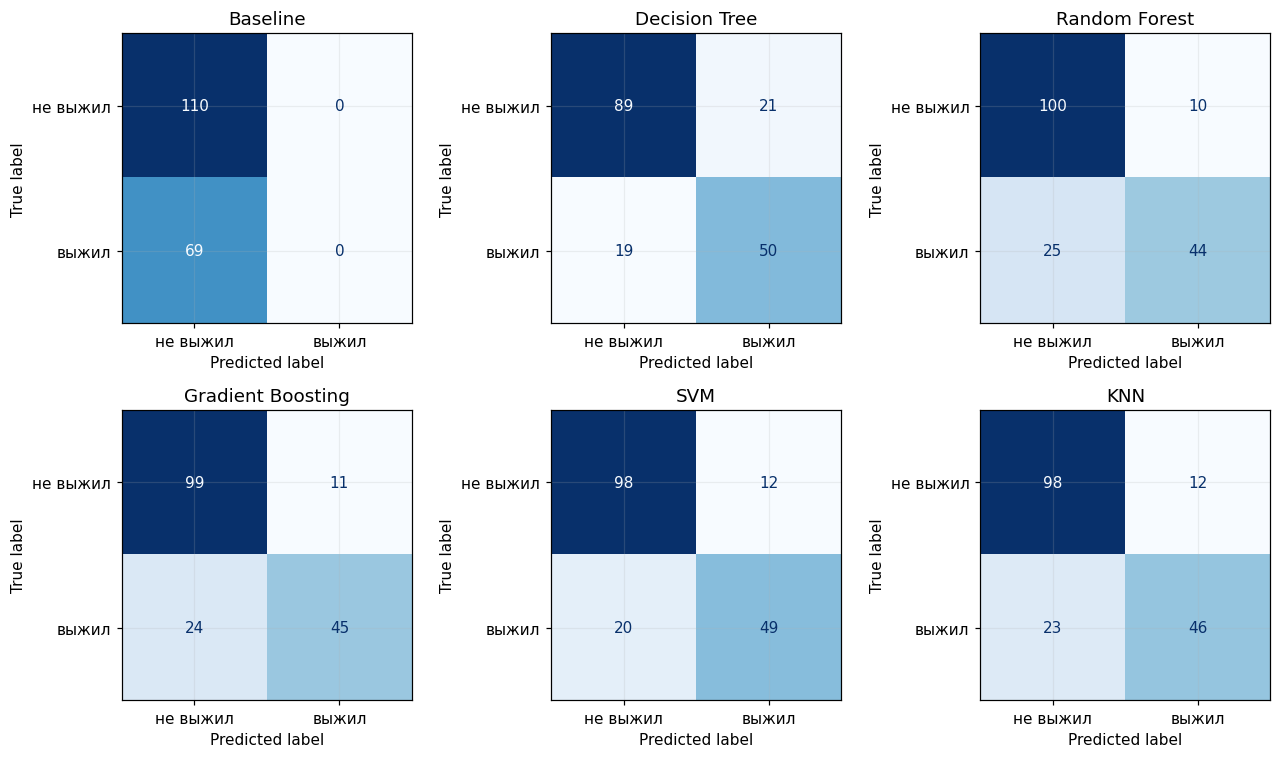

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (name, matrix) in zip(axes.flat, matrices.items()):
    ConfusionMatrixDisplay(matrix, display_labels=['не выжил', 'выжил']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d',
    )
    ax.set_title(name)
plt.tight_layout(); plt.show()

Строки матриц соответствуют истинным классам, столбцы — предсказанным. Внедиагональные элементы показывают ложные предположения о выживании и пропуски выживших.

## 12. Важность признаков у деревьев

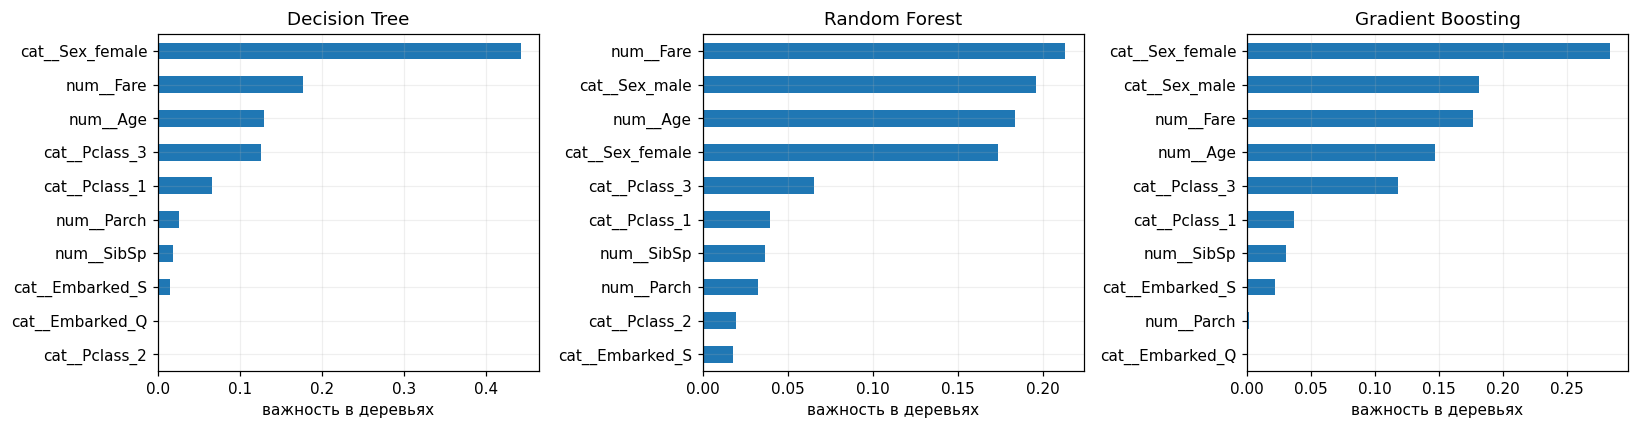

,Decision Tree,Random Forest,Gradient Boosting
0,cat__Sex_female,num__Fare,cat__Sex_female
1,num__Fare,cat__Sex_male,cat__Sex_male
2,num__Age,num__Age,num__Fare
3,cat__Pclass_3,cat__Sex_female,num__Age
4,cat__Pclass_1,cat__Pclass_3,cat__Pclass_3


In [17]:
tree_names = ['Decision Tree', 'Random Forest', 'Gradient Boosting']
importances = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, tree_names):
    model = models[name]
    feature_names = model.named_steps['preprocess'].get_feature_names_out()
    importance = pd.Series(model.named_steps['model'].feature_importances_, index=feature_names)
    importances[name] = importance.sort_values(ascending=False)
    importances[name].head(10).sort_values().plot.barh(ax=ax)
    ax.set_title(name)
    ax.set_xlabel('важность в деревьях')
plt.tight_layout(); plt.show()
display(pd.DataFrame({name: importance.head(5).index.tolist()
                      for name, importance in importances.items()}))

Среди важных признаков деревьев выделяются `Sex` и `Pclass`, что согласуется с результатами анализа данных. Эти оценки описывают вклад в прогноз, а причинные выводы требуют отдельного анализа.

## 13. Анализ ошибок SVM

In [18]:
chosen = test_predictions[winner_name]
error_table = X_test.copy()
error_table.insert(0, 'PassengerId', data.loc[X_test.index, 'PassengerId'])
error_table['факт'] = y_test.to_numpy()
error_table['прогноз'] = chosen
error_table['тип ошибки'] = np.select(
    [(error_table['факт'] == 0) & (error_table['прогноз'] == 1),
     (error_table['факт'] == 1) & (error_table['прогноз'] == 0)],
    ['false positive', 'false negative'], default='верно',
)
print(error_table['тип ошибки'].value_counts())
display(error_table.loc[error_table['тип ошибки'] != 'верно'].head(8))

тип ошибки
верно             147
false negative     20
false positive     12
Name: count, dtype: int64


,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,факт,прогноз,тип ошибки
553,554,3,male,22.0,0,0,7.2250,C,1,0,false negative
27,28,1,male,19.0,3,2,263.0000,S,0,1,false positive
279,280,3,female,35.0,1,1,20.2500,S,1,0,false negative
712,713,1,male,48.0,1,0,52.0000,S,1,0,false negative
455,456,3,male,29.0,0,0,7.8958,C,1,0,false negative
65,66,3,male,NaN,1,1,15.2458,C,1,0,false negative
489,490,3,male,9.0,1,1,15.9000,S,1,0,false negative
297,298,1,female,2.0,1,2,151.5500,S,0,1,false positive


In [19]:
by_group = error_table.groupby(['Sex', 'Pclass']).agg(
    пассажиров=('факт', 'size'),
    ошибок=('тип ошибки', lambda values: (values != 'верно').sum()),
)
by_group['доля ошибок'] = by_group['ошибок'] / by_group['пассажиров']
display(by_group)

пассажиров  ошибок  доля ошибок
Sex    Pclass                                 
female 1               15       1       0.0667
       2               18       1       0.0556
       3               28       9       0.3214
male   1               30      10       0.3333
       2               16       3       0.1875
       3               72       8       0.1111

На локальном тесте SVM дала 12 ложноположительных и 20 ложноотрицательных прогнозов. Оценки по малым группам менее устойчивы из-за небольшого числа наблюдений.

## 14. Итоги

SVM показала наилучший средний F1 на обучающей кросс-валидации (0,7543). Её локальный тестовый F1 составил 0,7538. Результат конкурсной посылки за 7 ноября 2026 г. на публичной части [лидерборда Kaggle](https://www.kaggle.com/competitions/lab-number-2-titanic-2026/leaderboard) — **0,747663**. Это отдельная оценка от локального теста.